# 07 · Denoising Diffusion Probabilistic Models (DDPM)

**Proses maju (tetap, tidak dilatih):** sedikit demi sedikit menambahkan *noise* Gaussian ke gambar selama T langkah, sampai gambarnya jadi noise murni.
q(x_t | x_0) = N( √ᾱ_t · x_0, (1 − ᾱ_t) I ), dengan ᾱ_t = Π (1 − β_s)

**Yang dilatih:** jaringan U-Net ε_θ(x_t, t) yang **menebak noise** yang ditambahkan.
**Loss (L_simple):** L = 𝔼 ‖ ε − ε_θ( √ᾱ_t x_0 + √(1−ᾱ_t) ε, t ) ‖²

**Proses balik (sampling):** mulai dari noise murni x_T ~ N(0, I), lalu buang noise sedikit demi sedikit selama T langkah:
x_{t−1} = (1/√α_t) · ( x_t − β_t/√(1−ᾱ_t) · ε_θ(x_t, t) ) + σ_t z

> **Ide utama (loss → perilaku):**
> Berbeda dengan GAN, loss DDPM adalah **regresi biasa dengan target yang jelas**: noise ε yang kita tambahkan sendiri. Tidak ada lawan yang ikut bergerak. Akibatnya **training sangat stabil**, mirip melatih model supervised biasa.
> Karena setiap langkah hanya membersihkan noise sedikit, model bisa membangun gambar secara bertahap dan detail. Hasilnya **tajam dan beragam** (mode coverage tinggi, karena loss menutupi seluruh data, tidak ada "curang" seperti mode collapse).
> Harga yang dibayar: menghasilkan satu gambar butuh **T = 1000 kali** menjalankan U-Net, sehingga **paling lambat**. Inilah sisi "*Sampling Speed*" pada *Generative Trilemma*.

In [1]:
%run ./00_helpers.ipynb

device = cuda | dataset = fashion_mnist | QUICK = False
folder proyek = c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN
hasil -> c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results
Helpers siap ✔


c:\Users\Derry\Anaconda\envs\deep-learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Dataset

In [2]:
set_seed()
splits = load_splits()
loaders = make_loaders(splits)
x_test, y_test = splits["test"]

Jumlah data: {'train': 56000, 'val': 7000, 'test': 7000}


## 2. Hyperparameter

In [3]:
T = 50 if QUICK else 1000        # jumlah langkah difusi
BETA_START, BETA_END = 1e-4, 0.02
BASE_CH = 64
MAX_EPOCHS = n_epochs(40)
LEARNING_RATE = 2e-4
EMA_DECAY = 0.999                # bobot rata-rata bergerak untuk sampling yang lebih halus

## 3. Model: U-Net Kecil + Time Embedding

- **Time embedding sinusoidal:** memberi tahu jaringan sedang berada di langkah t ke berapa.
- **ResBlock + GroupNorm:** blok konvolusi dengan *skip connection*.
- **Self-attention** di resolusi 7×7.
- Resolusi: 28 → 14 → 7 → 14 → 28, dengan *skip connection* U-Net.

In [4]:
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / (half - 1))
        args = t.float()[:, None] * freqs[None]
        return torch.cat([args.sin(), args.cos()], dim=1)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, temb_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.temb = nn.Linear(temb_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.drop = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.temb(F.silu(temb))[:, :, None, None]
        h = self.conv2(self.drop(F.silu(self.norm2(h))))
        return h + self.skip(x)


class SelfAttention(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1)
        self.proj = nn.Conv2d(ch, ch, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        q, k, v = self.qkv(self.norm(x)).reshape(b, 3, c, h * w).unbind(1)
        attn = torch.softmax(q.transpose(1, 2) @ k / math.sqrt(c), dim=-1)
        return x + self.proj((v @ attn.transpose(1, 2)).reshape(b, c, h, w))


class UNet(nn.Module):
    def __init__(self, base=64, mults=(1, 2, 2), dropout=0.1):
        super().__init__()
        temb_dim = base * 4
        self.time_mlp = nn.Sequential(SinusoidalPosEmb(base), nn.Linear(base, temb_dim),
                                      nn.SiLU(), nn.Linear(temb_dim, temb_dim))
        self.init_conv = nn.Conv2d(1, base, 3, padding=1)
        chs = [base * m for m in mults]
        self.downs, cur = nn.ModuleList(), base
        for i, ch in enumerate(chs):
            down = nn.Conv2d(ch, ch, 3, stride=2, padding=1) if i < len(chs) - 1 else nn.Identity()
            self.downs.append(nn.ModuleList([ResBlock(cur, ch, temb_dim, dropout),
                                             ResBlock(ch, ch, temb_dim, dropout), down]))
            cur = ch
        self.mid1 = ResBlock(cur, cur, temb_dim, dropout)
        self.mid_attn = SelfAttention(cur)
        self.mid2 = ResBlock(cur, cur, temb_dim, dropout)
        self.ups = nn.ModuleList()
        for i in reversed(range(len(chs))):
            ch = chs[i]
            up = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                               nn.Conv2d(ch, ch, 3, padding=1)) if i > 0 else nn.Identity()
            self.ups.append(nn.ModuleList([ResBlock(cur + ch, ch, temb_dim, dropout),
                                           ResBlock(ch, ch, temb_dim, dropout), up]))
            cur = ch
        self.out = nn.Sequential(nn.GroupNorm(8, cur), nn.SiLU(), nn.Conv2d(cur, 1, 3, padding=1))

    def forward(self, x, t):
        temb = self.time_mlp(t)
        h = self.init_conv(x)
        skips = []
        for b1, b2, down in self.downs:
            h = b2(b1(h, temb), temb); skips.append(h); h = down(h)
        h = self.mid2(self.mid_attn(self.mid1(h, temb)), temb)
        for b1, b2, up in self.ups:
            h = torch.cat([h, skips.pop()], dim=1)
            h = up(b2(b1(h, temb), temb))
        return self.out(h)


model = UNet(BASE_CH).to(device)
ema_model = copy.deepcopy(model).eval()
for p in ema_model.parameters():
    p.requires_grad_(False)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print("Jumlah parameter U-Net:", count_params(model))

Jumlah parameter U-Net: 4659777


## 4. Proses Difusi & Loss Function

In [5]:
betas = torch.linspace(BETA_START, BETA_END, T, device=device)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

def q_sample(x0, t, noise):
    # proses maju: x_t = sqrt(abar_t) x_0 + sqrt(1 - abar_t) eps
    ab = alpha_bar[t][:, None, None, None]
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise

def ddpm_loss(net, x0, generator=None):
    t = torch.randint(0, T, (x0.size(0),), device=device, generator=generator)
    noise = torch.randn(x0.shape, device=device, generator=generator)
    return F.mse_loss(net(q_sample(x0, t, noise), t), noise)      # L_simple

@torch.no_grad()
def ema_update():
    for e, p in zip(ema_model.parameters(), model.parameters()):
        e.mul_(EMA_DECAY).add_(p.detach(), alpha=1 - EMA_DECAY)
    for e, b in zip(ema_model.buffers(), model.buffers()):
        e.copy_(b)

@torch.no_grad()
def sample(net, n, generator=None, record_steps=None):
    # proses balik: x_T ~ N(0, I) -> x_0, sebanyak T langkah
    x = torch.randn(n, *IMG_SHAPE, device=device, generator=generator)
    traj = {}
    for t in reversed(range(T)):
        eps = net(x, torch.full((n,), t, device=device, dtype=torch.long))
        mean = (x - betas[t] / (1 - alpha_bar[t]).sqrt() * eps) / alphas[t].sqrt()
        if t > 0:
            x = mean + betas[t].sqrt() * torch.randn(x.shape, device=device, generator=generator)
        else:
            x = mean
        if record_steps is not None and t in record_steps:
            traj[t] = to_01(x.clamp(-1, 1)).cpu()
    x = to_01(x.clamp(-1, 1))
    return (x, traj) if record_steps is not None else x

## 5. Training

In [6]:
history = {"model": "ddpm", "params": count_params(model), "T": T, "epoch": [], "iter_loss": [],
           "epoch_time_s": [], "train": [], "val": []}

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    t0 = time.perf_counter()
    total, n = 0.0, 0
    for it, (x, _) in enumerate(tqdm(loaders["train"], desc=f"epoch {epoch}", leave=False)):
        loss = ddpm_loss(model, to_pm1(x.to(device)))
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        ema_update()
        total += loss.item(); n += 1
        if it % 10 == 0:
            history["iter_loss"].append(loss.item())
    sync()
    history["epoch_time_s"].append(time.perf_counter() - t0)
    history["train"].append({"loss": total / n})

    # validasi (pakai t & noise dengan seed tetap supaya bisa dibandingkan antar epoch)
    g = torch.Generator(device=device).manual_seed(SEED)
    with torch.no_grad():
        vl = np.mean([ddpm_loss(ema_model, to_pm1(x.to(device)), g).item() for x, _ in loaders["val"]])
    history["val"].append({"loss": float(vl)})
    history["epoch"].append(epoch)
    print(f"Epoch[{epoch}/{MAX_EPOCHS}] Train noise-MSE: {total / n:.4f}  Val noise-MSE (EMA): {vl:.4f}  "
          f"({history['epoch_time_s'][-1]:.1f}s)")

torch.save({"model": model.state_dict(), "ema": ema_model.state_dict(), "T": T}, CKPT_DIR / "ddpm.pt")

Epoch[1/40] Train noise-MSE: 0.0855  Val noise-MSE (EMA): 0.1775  (71.0s)


Epoch[2/40] Train noise-MSE: 0.0505  Val noise-MSE (EMA): 0.0873  (72.6s)


Epoch[3/40] Train noise-MSE: 0.0462  Val noise-MSE (EMA): 0.0680  (71.8s)


Epoch[4/40] Train noise-MSE: 0.0443  Val noise-MSE (EMA): 0.0548  (72.2s)


Epoch[5/40] Train noise-MSE: 0.0428  Val noise-MSE (EMA): 0.0468  (74.0s)


Epoch[6/40] Train noise-MSE: 0.0420  Val noise-MSE (EMA): 0.0424  (74.0s)


... (30 outputs left out)

Epoch[37/40] Train noise-MSE: 0.0355  Val noise-MSE (EMA): 0.0336  (74.6s)


Epoch[38/40] Train noise-MSE: 0.0352  Val noise-MSE (EMA): 0.0336  (74.5s)


Epoch[39/40] Train noise-MSE: 0.0358  Val noise-MSE (EMA): 0.0335  (74.8s)


Epoch[40/40] Train noise-MSE: 0.0355  Val noise-MSE (EMA): 0.0335  (74.4s)


## 6. Plot Loss History

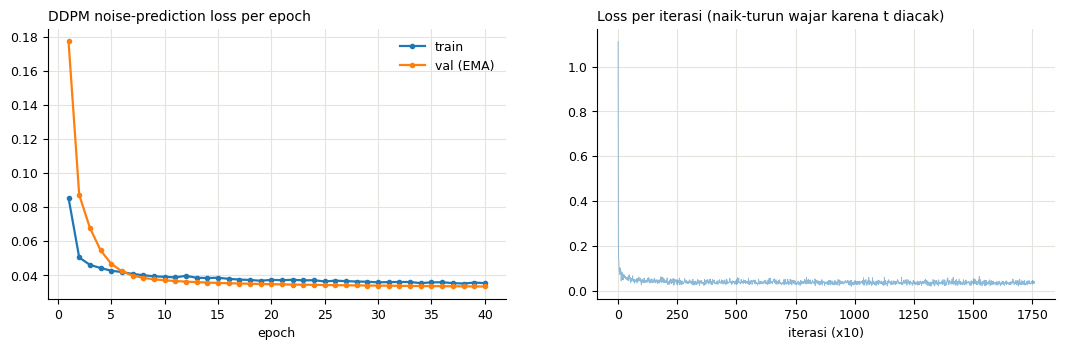

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(history["epoch"], [e["loss"] for e in history["train"]], "-o", ms=3, label="train")
axes[0].plot(history["epoch"], [e["loss"] for e in history["val"]], "-o", ms=3, label="val (EMA)")
axes[0].set_title("DDPM noise-prediction loss per epoch", loc="left"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(history["iter_loss"], lw=0.6, alpha=0.5)
axes[1].set_title("Loss per iterasi (naik-turun wajar karena t diacak)", loc="left"); axes[1].set_xlabel("iterasi (x10)")
plt.show()

## 7. Trajektori Reverse Diffusion x_T → x_0 (untuk Figur 5)
Gambar terbentuk **bertahap dari noise**: bentuk kasar muncul dulu, detail muncul belakangan.

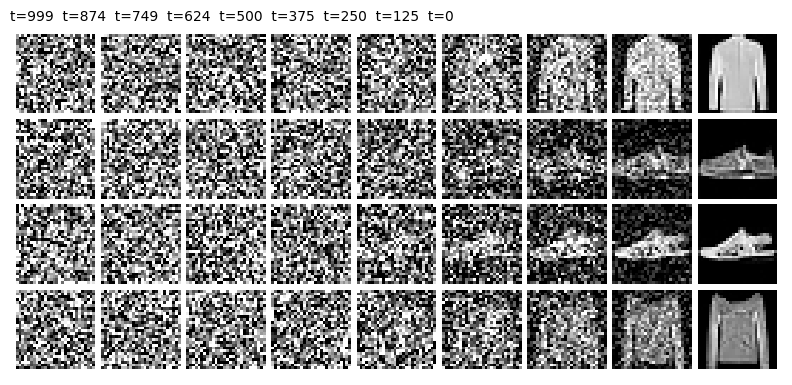

In [8]:
steps = sorted({int(round(s)) for s in np.linspace(T - 1, 0, 9)}, reverse=True)
g = torch.Generator(device=device).manual_seed(SEED)
_, traj = sample(ema_model, 4, g, record_steps=steps)
traj_grid = torch.stack([traj[s] for s in steps], 1).reshape(-1, *IMG_SHAPE)   # baris = sampel, kolom = langkah
fig, ax = plt.subplots(figsize=(10, 4.5))
show_imgs(ax, traj_grid, nrow=len(steps), title="  ".join(f"t={s}" for s in steps))
plt.show()

## 8. Evaluasi: Sampling, FID, Mode Coverage, Latency

⚠️ Bagian ini **paling lama**, karena setiap sampel butuh T = 1000 langkah. Kalau terlalu lama, kecilkan `FID_NUM_SAMPLES` di notebook 00. Pakai angka yang sama untuk semua model supaya FID-nya adil.

sampling FID: 100%|██████████| 20/20 [34:34<00:00, 103.73s/it]


FID           : 9.542400900274004
Mode coverage : {'class_hist': [0.12219999730587006, 0.10599999874830246, 0.09839999675750732, 0.10180000215768814, 0.10360000282526016, 0.07999999821186066, 0.06960000097751617, 0.12939999997615814, 0.0868000015616417, 0.10220000147819519], 'entropy_norm': 0.9935802817344666, 'modes_covered': 10}
Latency       : 21023.2 ms / batch 64 | 14283.7 ms / 1 sampel


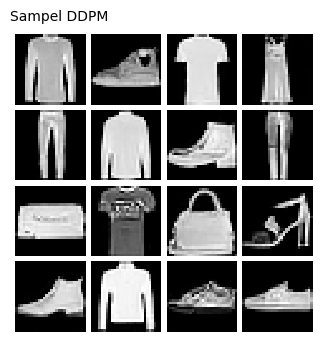

In [9]:
clf = load_mlp_classifier()
g = torch.Generator(device=device).manual_seed(SEED)
samples = torch.cat([sample(ema_model, min(250, FID_NUM_SAMPLES - i), g).cpu()
                     for i in tqdm(range(0, FID_NUM_SAMPLES, 250), desc="sampling FID")])

metrics = {"model": "ddpm", "params": count_params(model), "latent_dim": "1x28x28 (dimensi citra)", "T": T,
           "train_time_per_epoch_s": float(np.mean(history["epoch_time_s"]))}
metrics["fid"] = compute_fid(samples, splits)
metrics["mode_coverage"] = mode_coverage(samples, clf)
# latency: seluruh T langkah, cukup 3 kali ulang karena lama
t64 = []; t1 = []
for _ in range(1 if QUICK else 3):
    for lst, nn_ in [(t64, LATENCY_BATCH), (t1, 1)]:
        sync(); t0 = time.perf_counter(); sample(ema_model, nn_); sync()
        lst.append((time.perf_counter() - t0) * 1000)
metrics["latency_ms_batch64"], metrics["latency_ms_batch64_std"] = float(np.mean(t64)), float(np.std(t64))
metrics["latency_ms_batch1"], metrics["latency_ms_batch1_std"] = float(np.mean(t1)), float(np.std(t1))
metrics["latency_mode"] = f"sampling iteratif {T} langkah"
metrics["stability"] = stability_summary(history)
metrics["hparams"] = {"epochs": len(history["epoch"]), "lr": LEARNING_RATE, "batch_size": BATCH_SIZE,
                      "T": T, "beta_start": BETA_START, "beta_end": BETA_END, "base_ch": BASE_CH, "ema": EMA_DECAY}

print(f"FID           : {metrics['fid']}")
print(f"Mode coverage : {metrics['mode_coverage']}")
print(f"Latency       : {metrics['latency_ms_batch64']:.1f} ms / batch 64 | {metrics['latency_ms_batch1']:.1f} ms / 1 sampel")
fig, ax = plt.subplots(figsize=(4, 4)); show_imgs(ax, samples[:16], nrow=4, title="Sampel DDPM"); plt.show()

## 9. Simpan Hasil untuk Laporan

In [10]:
save_results("ddpm", metrics,
             artifacts={"samples16": samples[:16], "traj_grid": traj_grid, "traj_steps": steps},
             history=history)

Hasil 'ddpm' tersimpan di c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results/
